In [1]:
import io

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from skimage import data
from sklearn.cluster import KMeans

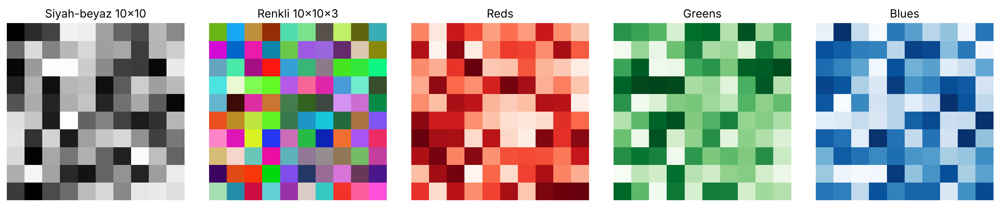

In [2]:
image_bw = np.random.uniform(low=0, high=255, size=100).reshape((10, 10))
image_c = np.random.uniform(low=0., high=1., size=100 * 3).reshape((10, 10, 3))

fig, axs = plt.subplots(1, 5, figsize=(15, 3))
axs[0].imshow(image_bw, cmap="gray")
axs[0].set_title("Siyah-beyaz 10x10")
axs[1].imshow(image_c)
axs[1].set_title("Renkli 10x10x3")
for i, cmap in enumerate(["Reds", "Greens", "Blues"]):
    axs[i + 2].imshow(image_c[:, :, i], cmap=cmap)
    axs[i + 2].set_title(cmap)
for ax in axs:
    ax.axis("off")
plt.tight_layout()
plt.show()

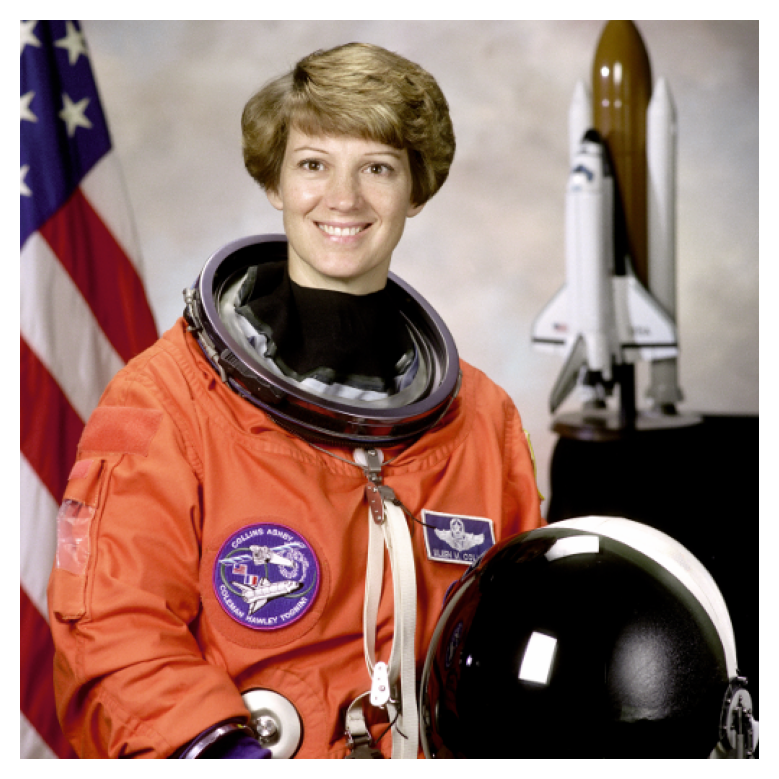

img_shape: (512, 512, 3) | tür: uint8


In [3]:
img = data.astronaut()
img_shape = img.shape

plt.imshow(img)
plt.axis("off")
plt.show()
print("img_shape:", img_shape, "| tür:", img.dtype)

In [4]:
X = img.reshape(-1, 3)
color_count = len(np.unique(X, axis=0))

print("X:", X.shape)
print("color_count:", color_count)
print(f"Olası renk sayısı 256^3 = {256 ** 3:,} | piksel sayısı = {X.shape[0]:,}")

X: (262144, 3)
color_count: 113382
Olası renk sayısı 256^3 = 16,777,216 | piksel sayısı = 262,144


In [5]:
kmeans = KMeans(n_clusters=32, random_state=42).fit(X)

print("labels_:", kmeans.labels_.shape, "| benzersiz etiket:", len(np.unique(kmeans.labels_)))
print("cluster_centers_:", kmeans.cluster_centers_.shape)
print("İlk merkez (RGB):", kmeans.cluster_centers_[0].round(1))

labels_: (262144,) | benzersiz etiket: 32
cluster_centers_: (32, 3)
İlk merkez (RGB): [236.5 231.  234.3]


In [6]:
X_compressed = kmeans.cluster_centers_[kmeans.labels_]
X_compressed = np.rint(X_compressed).astype("uint8")

print("X_compressed:", X_compressed.shape, X_compressed.dtype)
print("Benzersiz renk:", len(np.unique(X_compressed, axis=0)))

X_compressed: (262144, 3) uint8


Benzersiz renk: 32


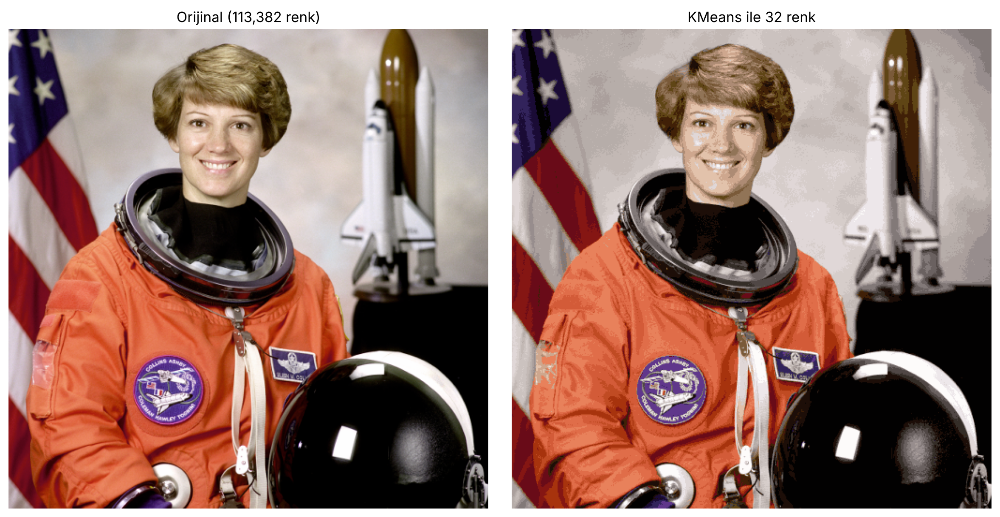

In [7]:
img_compressed = X_compressed.reshape(img_shape)

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
axes[0].imshow(img)
axes[0].set_title(f"Orijinal ({color_count:,} renk)")
axes[1].imshow(img_compressed)
axes[1].set_title("KMeans ile 32 renk")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

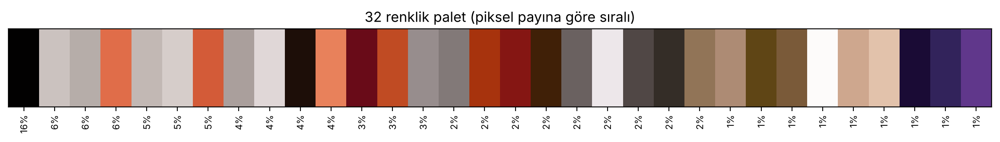

In [8]:
palette = kmeans.cluster_centers_.round().astype("uint8")
share = np.bincount(kmeans.labels_) / len(kmeans.labels_)
order = np.argsort(-share)

plt.figure(figsize=(12, 1.8))
plt.imshow(palette[order][None, :, :], aspect="auto")
plt.yticks([])
plt.xticks(range(32), [f"{s:.0%}" for s in share[order]], rotation=90, fontsize=8)
plt.title("32 renklik palet (piksel payına göre sıralı)")
plt.tight_layout()
plt.show()

In [9]:
def png_size(image):
    buffer = io.BytesIO()
    image.save(buffer, format="PNG", optimize=True)
    return buffer.tell()

def palette_image(labels, centers):
    image = Image.fromarray(labels.reshape(img_shape[:2]).astype("uint8"), mode="P")
    image.putpalette(np.rint(centers).astype("uint8").flatten().tolist())
    return image

def psnr(original, compressed):
    mse = ((original.astype(float) - compressed.astype(float)) ** 2).mean()
    return 10 * np.log10(255 ** 2 / mse)

raw_bytes = img.size
original_png = png_size(Image.fromarray(img))

print(f"Ham boyut: {raw_bytes / 1024:.0f} KB (piksel başına 24 bit)")
print(f"Orijinal PNG: {original_png / 1024:.0f} KB")
print(f"32 renk teorik boyut: {(X.shape[0] * np.log2(32) / 8 + 32 * 3) / 1024:.0f} KB (piksel başına 5 bit + palet)")
palette_32 = palette_image(kmeans.labels_, kmeans.cluster_centers_)
print("Paletli PNG görüntüyle birebir aynı mı:", np.array_equal(np.array(palette_32.convert("RGB")), img_compressed))
print(f"32 renk PNG (paletli): {png_size(palette_32) / 1024:.0f} KB")
print(f"PSNR: {psnr(img, img_compressed):.1f} dB")

Ham boyut: 768 KB (piksel başına 24 bit)
Orijinal PNG: 412 KB
32 renk teorik boyut: 160 KB (piksel başına 5 bit + palet)
Paletli PNG görüntüyle birebir aynı mı: True
32 renk PNG (paletli): 53 KB
PSNR: 30.8 dB


In [10]:
k_values = [2, 4, 8, 16, 32, 64, 128]
results = []
compressed_images = {}

for k in k_values:
    model = KMeans(n_clusters=k, random_state=42, n_init=1).fit(X)
    compressed = np.rint(model.cluster_centers_[model.labels_]).astype("uint8").reshape(img_shape)
    compressed_images[k] = compressed
    results.append({
        "k": k,
        "inertia": model.inertia_,
        "RMSE": np.sqrt(((img.astype(float) - compressed) ** 2).mean()),
        "PSNR_dB": psnr(img, compressed),
        "bit/piksel": np.log2(k),
        "teorik_KB": (X.shape[0] * np.log2(k) / 8 + k * 3) / 1024,
        "PNG_KB": png_size(palette_image(model.labels_, model.cluster_centers_)) / 1024,
    })

results = pd.DataFrame(results)
results["sıkıştırma_oranı"] = original_png / 1024 / results["PNG_KB"]
results.round(2)

,k,inertia,RMSE,PSNR_dB,bit/piksel,teorik_KB,PNG_KB,sıkıştırma_oranı
0,2,1.509788e+09,43.82,15.30,1.0,32.01,7.88,52.32
1,4,5.564113e+08,26.60,19.63,2.0,64.01,12.40,33.27
2,8,2.067656e+08,16.22,23.93,3.0,96.02,28.60,14.42
3,16,8.810320e+07,10.59,27.63,4.0,128.05,41.07,10.04
4,32,4.262641e+07,7.37,30.79,5.0,160.09,53.39,7.72
5,64,2.206936e+07,5.31,33.64,6.0,192.19,73.25,5.63
6,128,1.237912e+07,3.98,36.14,7.0,224.38,96.35,4.28


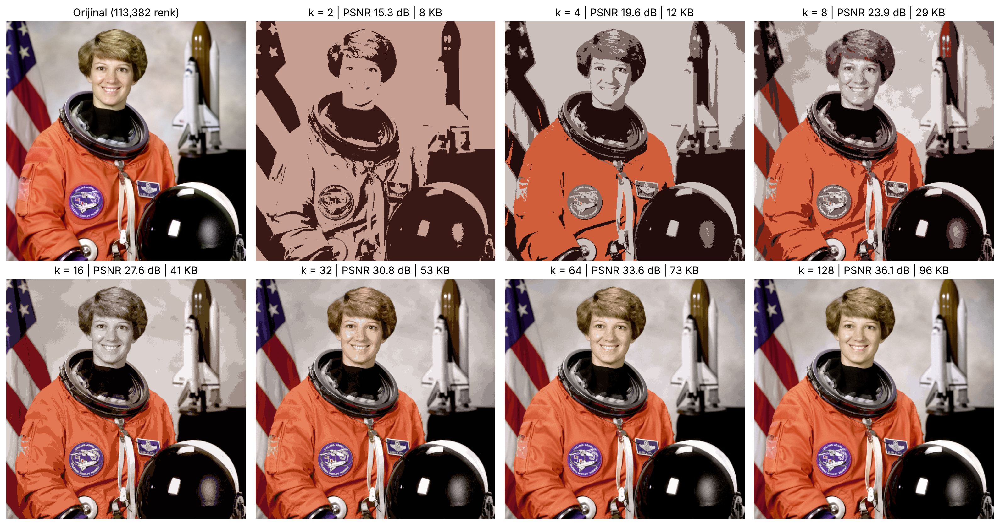

In [11]:
fig, axes = plt.subplots(2, 4, figsize=(16, 8.5))
axes[0, 0].imshow(img)
axes[0, 0].set_title(f"Orijinal ({color_count:,} renk)")
for ax, k in zip(axes.flat[1:], k_values):
    ax.imshow(compressed_images[k])
    row = results.set_index("k").loc[k]
    ax.set_title(f"k = {k} | PSNR {row['PSNR_dB']:.1f} dB | {row['PNG_KB']:.0f} KB")
for ax in axes.flat:
    ax.axis("off")
plt.tight_layout()
plt.show()

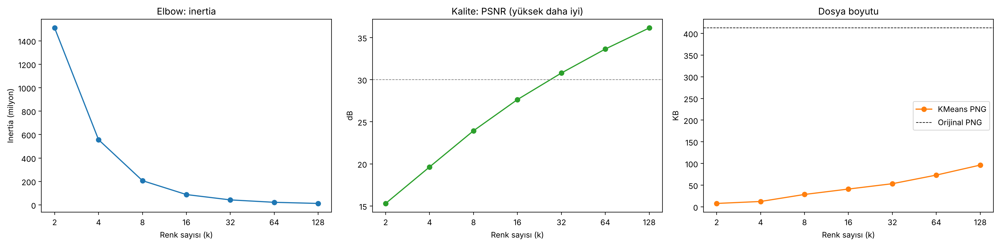

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
axes[0].plot(results["k"], results["inertia"] / 1e6, marker="o")
axes[0].set_title("Elbow: inertia")
axes[0].set_ylabel("Inertia (milyon)")
axes[1].plot(results["k"], results["PSNR_dB"], marker="o", color="tab:green")
axes[1].axhline(30, color="gray", linestyle="--", linewidth=0.8)
axes[1].set_title("Kalite: PSNR (yüksek daha iyi)")
axes[1].set_ylabel("dB")
axes[2].plot(results["k"], results["PNG_KB"], marker="o", color="tab:orange", label="KMeans PNG")
axes[2].axhline(original_png / 1024, color="black", linestyle="--", linewidth=0.8, label="Orijinal PNG")
axes[2].set_title("Dosya boyutu")
axes[2].set_ylabel("KB")
axes[2].legend()
for ax in axes:
    ax.set_xscale("log", base=2)
    ax.set_xticks(k_values)
    ax.set_xticklabels(k_values)
    ax.set_xlabel("Renk sayısı (k)")
plt.tight_layout()
plt.show()

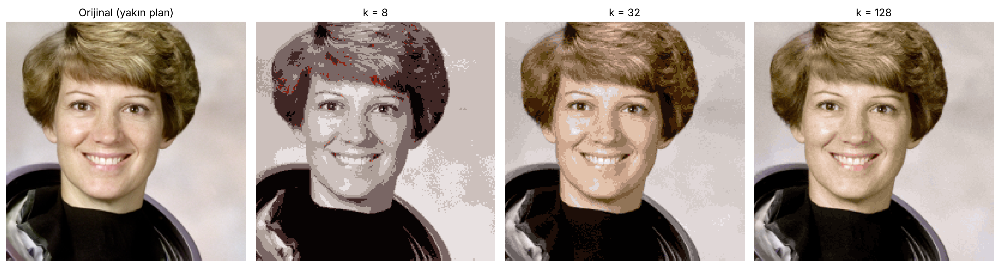

In [13]:
crop = (slice(30, 230), slice(140, 340))

fig, axes = plt.subplots(1, 4, figsize=(16, 4.5))
axes[0].imshow(img[crop])
axes[0].set_title("Orijinal (yakın plan)")
for ax, k in zip(axes[1:], [8, 32, 128]):
    ax.imshow(compressed_images[k][crop])
    ax.set_title(f"k = {k}")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

## Sonuç

- **Görüntü veri olarak:** Siyah-beyaz bir görüntü 0-255 değerlerden oluşan bir matris, renkli bir görüntü ise üst üste binmiş üç matris (kırmızı, yeşil, mavi). `astronaut` görüntüsü 512 × 512 × 3 (`img_shape`). Her piksel bir gözlem, her renk kanalı bir özellik kabul edilince `X` 262.144 × 3 boyutunda oluyor. Olası 16,7 milyon rengin 113.382'si bu görüntüde kullanılıyor (`color_count`).

- **32 renkle sıkıştırma:** KMeans pikselleri RGB uzayında 32 kümeye ayırdı. Her kümenin merkezi o kümedeki piksellerin ortalama rengi ve her piksel kendi küme merkezinin rengiyle değiştirildi (`X_compressed`, 32 benzersiz renk, `uint8`). Sıkıştırılmış görüntüde kişi, kıyafet, bayrak ve uzay mekiği açıkça tanınıyor. Ortalama piksel hatası 7.4 (0-255 ölçeğinde), PSNR 30.8 dB. Kayıp en çok yüz ve arka plan gibi yumuşak renk geçişlerinde, renk bantları olarak görülüyor.

- **Dosya boyutu:** Ham görüntü 768 KB (piksel başına 24 bit), orijinal PNG 412 KB. 32 renkte her piksel 5 bitlik bir palet numarası olarak saklanabilir: teorik boyut 160 KB. Paletli PNG ise 53 KB, orijinal PNG'den 7.7 kat küçük. PNG ayrıca tekrar eden renkleri sıkıştırdığı için az renk iki kat kazanç sağlıyor. Paletli PNG'nin ürettiğimiz görüntüyle piksel piksel aynı olduğu kontrol edildi.

- **Farklı k değerleri:**

| k | PSNR (dB) | PNG (KB) | Orijinal PNG'ye göre |
|---|---|---|---|
| 2 | 15.3 | 8 | 52 kat küçük |
| 4 | 19.6 | 12 | 33 kat |
| 8 | 23.9 | 29 | 14 kat |
| 16 | 27.6 | 41 | 10 kat |
| 32 | 30.8 | 53 | 7.7 kat |
| 64 | 33.6 | 73 | 5.6 kat |
| 128 | 36.1 | 96 | 4.3 kat |

  k = 2'de görüntü iki tonlu bir siluete dönüşüyor. k = 4'te turuncu kıyafet ortaya çıkıyor ama ten ve saç griye kayıyor. k = 8'de yüz tanınıyor, fakat ten rengi gri ve saçta yanlış kırmızı lekeler var. k = 16'dan itibaren görüntü doğal görünmeye başlıyor. k = 32'de yakın plan bakınca yüzde hafif bantlar seçiliyor, k = 64 ve 128 ise gözle orijinalden zor ayırt ediliyor.

- **Elbow ve seçim:** Inertia k = 2'den 16'ya 17 kat düşüyor, sonra her ikiye katlamada yaklaşık yarıya iniyor. Belirgin tek bir dirsek yok; eğri yavaşça yatıklaşıyor. PSNR ise k her ikiye katlandığında yaklaşık 3 dB artıyor, dosya boyutu da benzer şekilde düzenli büyüyor. Bu görüntü için iyi bir denge **k = 32**: PSNR 30 dB'nin üzerinde (genelde "iyi kalite" sınırı kabul edilir) ve dosya orijinal PNG'nin 1/8'i. Kalite öncelikliyse 64, boyut öncelikliyse 16 seçilebilir.

- **Sınırlılıklar:** KMeans renkleri RGB uzayında öklid mesafesiyle grupluyor. Bu, insan gözünün renk farkını algılama biçimine tam uymuyor; Lab gibi algısal bir renk uzayında kümelemek daha doğal sonuç verebilir. Titreşim (dithering) kullanılmadığı için yumuşak geçişlerde bantlar oluşuyor. KMeans'i 262 bin piksel üzerinde eğitmek de bir maliyet (k = 128 için birkaç saniye) ve her görüntü kendi paletini gerektiriyor. Farklı k değerleri karşılaştırılırken hız için tek başlatma (`n_init=1`) kullanıldı; sonuçlar başlangıç noktasına göre biraz değişebilir.